# Step 6: Feature Selection
Isolation Forest picks a feature **at random** at every split, so two features that say the same thing count double. This step removes the copies.

| Part | What |
|---|---|
| A | The bulk buyers: the analysis behind removing 13 of them in notebook 04 (cell 5.1b) |
| B | Find features that carry the same information (correlation) and keep one of each |
| C | Final feature list → final reason codes |

**Input:** `data/processed/features.csv`
**Output:** the final feature list (used in Step 7)

In [1]:
# 6.1 Load the features from Step 5 and list the 10 feature columns.
# Expected: (209012, 17), because the 13 bulk buyers are already removed in notebook 04.
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/features.csv", parse_dates=["expense_date"])

FEATURES = [
    "log_amount",
    "amount_vs_employee", "amount_vs_employee_category", "amount_vs_department",
    "category_share_for_employee",
    "same_category_day_count", "duplicate_count", "daily_request_count",
    "is_weekend", "is_round_amount",
]
print("Loaded:", df.shape)

Loaded: (209012, 18)


## Part A: The bulk buyers
These cells are the analysis that led to removing 13 bulk buyers in notebook 04 (cell 5.1b). Before the removal they showed 13 busy employees with 15.7% of all requests. Now that `features.csv` no longer has them, they show **0 busy employees**, which confirms the removal worked.

In [2]:
# 6.2 "Usual day" per employee = the median number of requests on the days they submit something
# (median, so one crazy day doesn't change it). 92% of employees usually send 1 request a day.
# The loop shows how many employees, and what share of requests, are at or above 2, 3 and 5.
per_day = df.groupby(["requester_id", "expense_date"]).size()
usual_day = per_day.groupby("requester_id").median()

print(usual_day.value_counts().sort_index().head(8).to_dict())
for t in [2, 3, 5]:
    ids = usual_day[usual_day >= t].index
    print(f"Usual day >= {t}: {len(ids)} employees, {df['requester_id'].isin(ids).mean() * 100:.1f}% of requests")

{1.0: 4223, 1.5: 75, 2.0: 217, 2.5: 11, 3.0: 20, 3.5: 2, 4.0: 15, 4.5: 1}
Usual day >= 2: 266 employees, 23.6% of requests
Usual day >= 3: 38 employees, 6.1% of requests
Usual day >= 5: 0 employees, 0.0% of requests


In [3]:
# 6.3 Who are the busy ones (usual day >= 5)? Before the removal: 13 bulk travel / equipment buyers
# with 15.7% of all requests. Now the list is empty, so .assign() just lists every employee's
# usual_day with empty columns (that long output is expected).
BUSY_FROM = 5
busy_ids = usual_day[usual_day >= BUSY_FROM].index
is_busy = df["requester_id"].isin(busy_ids)
print("Busy employees:", len(busy_ids), "| their requests:", is_busy.sum(), f"({is_busy.mean() * 100:.1f}%)")

summary = (df[is_busy].groupby("requester_id")
             .agg(requests=("expense_id", "size"),
                  department=("department_id", "first"),
                  main_category=("category", lambda s: s.value_counts().index[0]),
                  biggest_day=("daily_request_count", "max"))
             .assign(usual_day=usual_day)
             .sort_values("requests", ascending=False))
print(summary.to_string())

Busy employees: 0 | their requests: 0 (0.0%)
              requests  department main_category  biggest_day  usual_day
requester_id                                                            
1001               NaN         NaN           NaN          NaN        1.0
1002               NaN         NaN           NaN          NaN        1.0
1003               NaN         NaN           NaN          NaN        1.0
1004               NaN         NaN           NaN          NaN        1.0
1005               NaN         NaN           NaN          NaN        1.0
1006               NaN         NaN           NaN          NaN        1.0
1007               NaN         NaN           NaN          NaN        1.0
1008               NaN         NaN           NaN          NaN        1.0
1009               NaN         NaN           NaN          NaN        1.0
1010               NaN         NaN           NaN          NaN        1.0
1011               NaN         NaN           NaN          NaN        1.0
1012  

In [4]:
# 6.4 Same-day counts for everyone else (False) vs the busy ones (True).
# Before the removal: a median of 1 same-category request per day vs 19. Now only the False row is left.
cols = ["same_category_day_count", "duplicate_count", "daily_request_count"]
print(df.groupby(is_busy)[cols].median())
print(df.groupby(is_busy)[cols].mean().round(2))

              same_category_day_count  duplicate_count  daily_request_count
requester_id                                                               
False                             1.0              1.0                  2.0
              same_category_day_count  duplicate_count  daily_request_count
requester_id                                                               
False                            2.76             1.28                  3.1


## Part B: Features that carry the same information
Isolation Forest picks a feature at random at every split, so two features that say the same thing give that idea double weight.
We measure how much two features move together with the correlation r (1 = copies, 0 = unrelated, -1 = opposite).
**Rule:** if |r| >= 0.9, keep only one of the two.

In [5]:
# 6.5 Correlation between every pair of features (Pearson r, from -1 to 1).
# The diagonal is always 1.00 (a feature compared with itself).
# SHORT = short names, only so the table fits on the screen.
SHORT = {"log_amount": "log_amt", "amount_vs_employee": "vs_emp",
         "amount_vs_employee_category": "vs_empcat", "amount_vs_department": "vs_dept",
         "category_share_for_employee": "cat_share", "same_category_day_count": "same_cat",
         "duplicate_count": "dup", "daily_request_count": "daily",
         "is_weekend": "weekend", "is_round_amount": "round"}

corr = df[FEATURES].corr()
print(corr.rename(index=SHORT, columns=SHORT).round(2).to_string())

           log_amt  vs_emp  vs_empcat  vs_dept  cat_share  same_cat   dup  daily  weekend  round
log_amt       1.00    0.82       0.75     0.98       0.02     -0.02 -0.04  -0.02    -0.03   0.10
vs_emp        0.82    1.00       0.92     0.84      -0.01     -0.04 -0.06  -0.04    -0.01   0.08
vs_empcat     0.75    0.92       1.00     0.77       0.00     -0.04 -0.07  -0.04    -0.01   0.07
vs_dept       0.98    0.84       0.77     1.00      -0.00     -0.02 -0.03  -0.02    -0.02   0.10
cat_share     0.02   -0.01       0.00    -0.00       1.00      0.18  0.04   0.13    -0.04  -0.02
same_cat     -0.02   -0.04      -0.04    -0.02       0.18      1.00  0.47   0.97    -0.01  -0.00
dup          -0.04   -0.06      -0.07    -0.03       0.04      0.47  1.00   0.45     0.07  -0.00
daily        -0.02   -0.04      -0.04    -0.02       0.13      0.97  0.45   1.00    -0.01  -0.00
weekend      -0.03   -0.01      -0.01    -0.02      -0.04     -0.01  0.07  -0.01     1.00  -0.01
round         0.10    0.08    

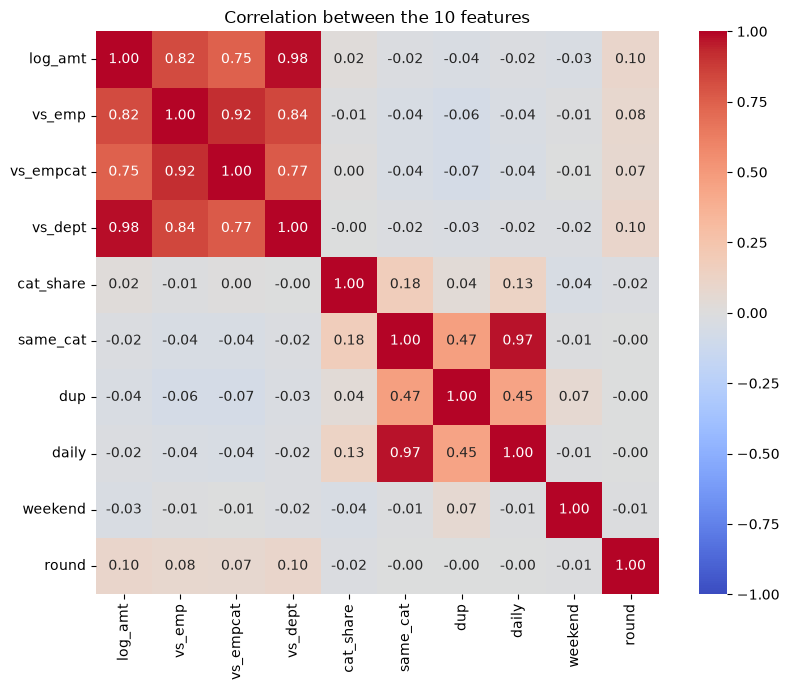

In [6]:
# 6.6 Heatmap of the same correlations:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 7))
sns.heatmap(corr.rename(index=SHORT, columns=SHORT), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation between the 10 features")
plt.tight_layout()
plt.show()

In [7]:
# 6.7 Every pair once (combinations = A-B but not B-A again), sorted by |r|.
# spearman = the same idea but on ranks (1st, 2nd, 3rd...), so a few huge values can't push it up.
# If both agree, the result is solid.
from itertools import combinations

pairs = pd.DataFrame([(a, b, corr.loc[a, b]) for a, b in combinations(FEATURES, 2)],
                     columns=["feature_1", "feature_2", "r"])
pairs["abs_r"] = pairs["r"].abs()
pairs["spearman"] = [df[a].corr(df[b], method="spearman")
                     for a, b in zip(pairs["feature_1"], pairs["feature_2"])]
print(pairs.sort_values("abs_r", ascending=False).head(8).round(3).to_string(index=False))

                  feature_1                   feature_2     r  abs_r  spearman
                 log_amount        amount_vs_department 0.978  0.978     0.981
    same_category_day_count         daily_request_count 0.972  0.972     0.885
         amount_vs_employee amount_vs_employee_category 0.922  0.922     0.946
         amount_vs_employee        amount_vs_department 0.844  0.844     0.881
                 log_amount          amount_vs_employee 0.823  0.823     0.865
amount_vs_employee_category        amount_vs_department 0.767  0.767     0.826
                 log_amount amount_vs_employee_category 0.748  0.748     0.810
    same_category_day_count             duplicate_count 0.470  0.470     0.407


In [8]:
# 6.8 Why is "amount vs the department" almost a copy of log_amount?
# amount_vs_department = (log_amount - department average) / department spread.
# If every department has a similar average and spread, that's just log_amount shifted and
# rescaled, so it moves exactly like log_amount and adds nothing new.
dept = df.groupby("department_id")["log_amount"].agg(["mean", "std"])
print(dept.describe().loc[["min", "max"]].round(2))

     mean   std
min  5.42  1.26
max  6.69  1.91


In [9]:
# 6.9 These two only differ when the employee's normal in THIS category is different from their
# normal overall. Count how often they're identical, then the cases where one says "very unusual"
# (> 3) and the other says "normal" (< 1): that's the only information each one adds.
same = df["amount_vs_employee"] == df["amount_vs_employee_category"]
print("Exactly the same value:", f"{same.mean():.1%}")

only_emp    = (df["amount_vs_employee"] > 3) & (df["amount_vs_employee_category"] < 1)
only_empcat = (df["amount_vs_employee_category"] > 3) & (df["amount_vs_employee"] < 1)
print("Unusual only vs the employee overall:", only_emp.sum())
print("Unusual only vs the employee in this category:", only_empcat.sum())

cols = ["requester_id", "category", "amount_sar", "baseline_level",
        "amount_vs_employee", "amount_vs_employee_category"]
print(df[only_empcat].sort_values("amount_vs_employee_category", ascending=False)[cols]
      .head(3).round(2).to_string(index=False))

Exactly the same value: 20.8%
Unusual only vs the employee overall: 6
Unusual only vs the employee in this category: 123
 requester_id       category  amount_sar baseline_level  amount_vs_employee  amount_vs_employee_category
         3876 Transportation     1148.47         empcat                0.91                         10.0
         3717         Travel      911.25         empcat                0.96                         10.0
         4376   IT & Telecom      371.25         empcat                0.33                         10.0


In [10]:
# 6.10 On most days people only use one category, so "requests today" and "requests today in this
# category" are the same number. Instead of deleting daily_request_count, subtract the overlap:
# other_category_day_count = requests the same day in OTHER categories.
# Then the two features no longer repeat each other, and nothing is lost.
same_day = df["daily_request_count"] == df["same_category_day_count"]
print("daily == same category:", f"{same_day.mean():.1%}")

df["other_category_day_count"] = df["daily_request_count"] - df["same_category_day_count"]
print(df["other_category_day_count"].value_counts().sort_index().head(6).to_dict())
print("Correlation with same_category_day_count:",
      round(df["other_category_day_count"].corr(df["same_category_day_count"]), 3))

daily == same category: 81.3%
{0: 169897, 1: 25127, 2: 7433, 3: 3071, 4: 1378, 5: 682}
Correlation with same_category_day_count: 0.067


In [11]:
# 6.11 Apply the 3 decisions and check that no pair is at 0.9 or above anymore.
DROP = ["amount_vs_department",   # copy of log_amount (6.8)
        "amount_vs_employee",     # covered by amount_vs_employee_category (6.9)
        "daily_request_count"]    # replaced by other_category_day_count (6.10)
SELECTED = [f for f in FEATURES if f not in DROP] + ["other_category_day_count"]

corr_sel = df[SELECTED].corr()
pairs_sel = pd.DataFrame([(a, b, abs(corr_sel.loc[a, b])) for a, b in combinations(SELECTED, 2)],
                         columns=["feature_1", "feature_2", "abs_r"])
print(len(SELECTED), "features:", SELECTED)
print(pairs_sel.sort_values("abs_r", ascending=False).head(3).round(3).to_string(index=False))

8 features: ['log_amount', 'amount_vs_employee_category', 'category_share_for_employee', 'same_category_day_count', 'duplicate_count', 'is_weekend', 'is_round_amount', 'other_category_day_count']
                  feature_1                   feature_2  abs_r
                 log_amount amount_vs_employee_category  0.748
    same_category_day_count             duplicate_count  0.470
category_share_for_employee     same_category_day_count  0.179


## Part C: Final features and reason codes
Each reason code the manager can see is connected to one of the 8 features. The three "amount is high" reasons all come from
`amount_vs_employee_category`; `baseline_level` (Step 5) says what the amount was compared with.
The final list is saved to `models/feature_list.json`, so training (Step 7) and the ML service (Step 9) use exactly the same features.

In [12]:
# 6.12 Connect each reason code (contract B7) to the feature that drives it.
# only_when = an extra condition from baseline_level (which history the amount was compared with):
#   empcat  → compared with the employee in this category → "higher than they usually request in this category"
#   emp     → the employee is new to this category → compared with the employee overall
#   deptcat → the employee is new (< 5 earlier requests) → compared with the department in this category
# unusual_category_for_employee only makes sense when the employee has their own history (empcat / emp);
# for new employees category_share_for_employee is the department's share, not theirs.
REASONS = [
    ("large_amount",                      "log_amount",                  "any"),
    ("amount_high_for_employee_category", "amount_vs_employee_category", "baseline_level == empcat"),
    ("amount_high_for_employee",          "amount_vs_employee_category", "baseline_level == emp"),
    ("amount_high_for_department",        "amount_vs_employee_category", "baseline_level == deptcat"),
    ("unusual_category_for_employee",     "category_share_for_employee", "baseline_level in (empcat, emp)"),
    ("possible_split_request",            "same_category_day_count",     "any"),
    ("duplicate_request",                 "duplicate_count",             "any"),
    ("many_requests_same_day",            "other_category_day_count",    "any"),
    ("weekend_expense",                   "is_weekend",                  "any"),
    ("round_amount",                      "is_round_amount",             "any"),
]
reasons = pd.DataFrame(REASONS, columns=["code", "feature", "only_when"])
print(reasons.to_string(index=False))

# Every selected feature must drive at least one reason, and no reason may use a dropped feature
assert set(reasons["feature"]) == set(SELECTED)

                             code                     feature                       only_when
                     large_amount                  log_amount                             any
amount_high_for_employee_category amount_vs_employee_category        baseline_level == empcat
         amount_high_for_employee amount_vs_employee_category           baseline_level == emp
       amount_high_for_department amount_vs_employee_category       baseline_level == deptcat
    unusual_category_for_employee category_share_for_employee baseline_level in (empcat, emp)
           possible_split_request     same_category_day_count                             any
                duplicate_request             duplicate_count                             any
           many_requests_same_day    other_category_day_count                             any
                  weekend_expense                  is_weekend                             any
                     round_amount             is_round_amoun

In [13]:
# 6.13 Which of the 3 amount reasons a request would get, based on its baseline_level.
# cat / none (the first days of the data, or a brand-new department-category pair) get no
# amount-vs-history reason; large_amount (log_amount) still covers a really big amount there.
amount_reason = df["baseline_level"].map({
    "empcat":  "amount_high_for_employee_category",
    "emp":     "amount_high_for_employee",
    "deptcat": "amount_high_for_department",
}).fillna("(no amount-vs-history reason)")
print((amount_reason.value_counts(normalize=True) * 100).round(1))

has_own_history = df["baseline_level"].isin(["empcat", "emp"])
print("Can get unusual_category_for_employee:", f"{has_own_history.mean():.1%}")

baseline_level
amount_high_for_employee_category    77.1
amount_high_for_employee             12.3
amount_high_for_department           10.2
(no amount-vs-history reason)         0.4
Name: proportion, dtype: float64
Can get unusual_category_for_employee: 89.3%


In [14]:
# 6.14 Save the final features, why the others were dropped, and the reason map to one small file.
# models/ is in git (unlike data/), so the team can see which features the model uses.
# Notebook 06 reads this file instead of re-typing the list. In Step 9 the ML service reads it too.
import json
import os

os.makedirs("../models", exist_ok=True)
feature_list = {
    "step": "6 - feature selection",
    "features": SELECTED,
    "dropped": {
        "amount_vs_department": "r = 0.98 with log_amount (departments have a similar normal)",
        "amount_vs_employee": "r = 0.92 with amount_vs_employee_category; adds only 6 unusual cases",
        "daily_request_count": "r = 0.97 with same_category_day_count; replaced by other_category_day_count",
    },
    "reasons": [{"code": c, "feature": f, "only_when": w} for c, f, w in REASONS],
}
with open("../models/feature_list.json", "w", encoding="utf-8") as fh:
    json.dump(feature_list, fh, indent=2)
print("Saved", len(SELECTED), "features and", len(REASONS), "reason codes to models/feature_list.json")

# Read it back the way notebook 06 will, and check it matches
with open("../models/feature_list.json", encoding="utf-8") as fh:
    check = json.load(fh)
print(check["features"] == SELECTED, df[check["features"]].shape)

Saved 8 features and 10 reason codes to models/feature_list.json
True (209012, 8)


## Result
- **Removed 13 bulk buyers** (usual day ≥ 5 requests, 15.7% of rows) in notebook 04 → 209,012 requests.
- **10 → 8 features** (rule: |r| ≥ 0.9 → keep one):
  - dropped `amount_vs_department` (r = 0.98 with `log_amount`)
  - dropped `amount_vs_employee` (r = 0.92 with `amount_vs_employee_category`, adds only 6 cases)
  - replaced `daily_request_count` (r = 0.97 with `same_category_day_count`) by `other_category_day_count` (r = 0.07)
- Highest remaining pair: `log_amount` / `amount_vs_employee_category`, r = 0.75: kept, they answer different questions.
- **All 10 reason codes stay**; each is connected to one feature (+ `baseline_level` for the 3 amount reasons).
- Saved: `models/feature_list.json`.